=== RECUENTO MATRICIAL ===
Verdaderos Negativos (TN): 190
Falsos Positivos     (FP): 64
Falsos Negativos     (FN): 3
Verdaderos Positivos (TP): 43

=== REPORTE DE CLASIFICACIÓN DETALLADO ===
              precision    recall  f1-score   support

  Normal (0)       0.98      0.75      0.85       254
   Falla (1)       0.40      0.93      0.56        46

    accuracy                           0.78       300
   macro avg       0.69      0.84      0.71       300
weighted avg       0.90      0.78      0.81       300



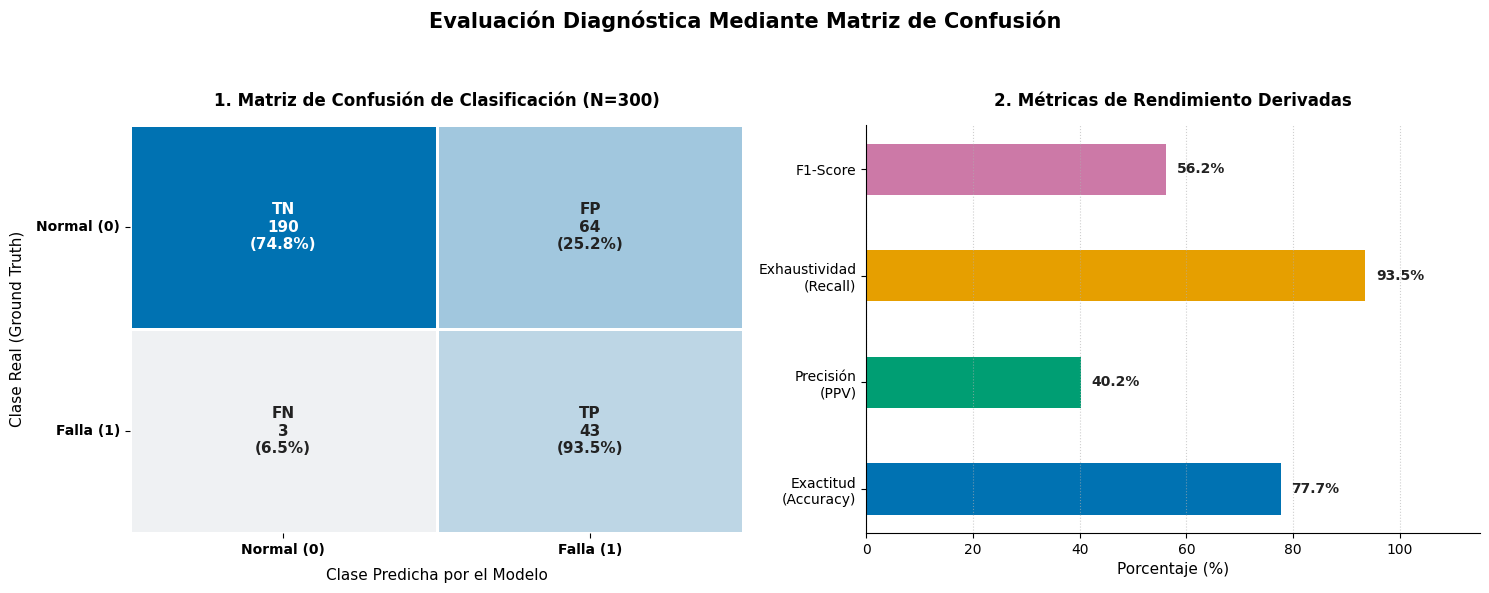

In [2]:
"""
Evaluación de Modelos mediante Matriz de Confusión.
Librerías: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. Simulación de datos industriales (85% Normal  vs. 15% Falla Crítica)
X, y = make_classification(
    n_samples=1000, n_features=8, n_informative=5, n_redundant=2,
    weights=[0.85, 0.15], random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Ajuste del modelo con ponderación de clases para mitigar desbalance
clf = LogisticRegression(class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 3. Cálculo formal de la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Normalización por fila (porcentaje de acierto por clase real)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

print("=== RECUENTO MATRICIAL ===")
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos     (FP): {fp}")
print(f"Falsos Negativos     (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}\n")

# 4. Cálculo de Métricas Derivadas
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Falla (1)']))

# 5. Visualización Gráfica (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel 1: Mapa térmico de la Matriz de Confusión
ax1.set_facecolor('white')
cmap_blues = sns.light_palette("#0072b2", as_cmap=True)

sns.heatmap(cm, annot=False, cmap=cmap_blues, cbar=False, ax=ax1, linewidths=2, linecolor='white')

# Textos dentro de cada celda con recuento y porcentaje
textos = [
    [f"TN\n{tn}\n({cm_norm[0, 0]*100:.1f}%)", f"FP\n{fp}\n({cm_norm[0, 1]*100:.1f}%)"],
    [f"FN\n{fn}\n({cm_norm[1, 0]*100:.1f}%)", f"TP\n{tp}\n({cm_norm[1, 1]*100:.1f}%)"]
]

for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > (cm.max() / 2) else "#222222"
        ax1.text(j + 0.5, i + 0.5, textos[i][j], ha='center', va='center',
                 fontsize=11, fontweight='bold', color=color)

ax1.set_title('1. Matriz de Confusión de Clasificación (N=300)', fontsize=12, fontweight='bold', pad=14)
ax1.set_xlabel('Clase Predicha por el Modelo', fontsize=11, labelpad=8)
ax1.set_ylabel('Clase Real (Ground Truth)', fontsize=11, labelpad=8)
ax1.set_xticklabels(['Normal (0)', 'Falla (1)'], fontsize=10, fontweight='bold')
ax1.set_yticklabels(['Normal (0)', 'Falla (1)'], fontsize=10, fontweight='bold', rotation=0)

# Panel 2: Barras horizontales de métricas derivadas
ax2.set_facecolor('white')
metricas = ['Exactitud\n(Accuracy)', 'Precisión\n(PPV)', 'Exhaustividad\n(Recall)', 'F1-Score']
valores = [
    accuracy_score(y_test, y_pred) * 100,
    precision_score(y_test, y_pred) * 100,
    recall_score(y_test, y_pred) * 100,
    f1_score(y_test, y_pred) * 100
]
colores = ['#0072b2', '#009e73', '#e69f00', '#cc79a7']

barras = ax2.barh(metricas, valores, color=colores, height=0.48)
ax2.set_xlim(0, 115)
ax2.set_xlabel('Porcentaje (%)', fontsize=11)
ax2.set_title('2. Métricas de Rendimiento Derivadas', fontsize=12, fontweight='bold', pad=14)
ax2.grid(axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

for b, v in zip(barras, valores):
    ax2.text(v + 2, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', ha='left',
             fontsize=10, fontweight='bold', color='#222222')

fig.suptitle('Evaluación Diagnóstica Mediante Matriz de Confusión', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [ ]:
# MAtriz confusion multiclasificación
"""
Matriz de Confusión Multiclase y Promedios (Macro, Micro, Weighted).
Librerías: scikit-learn, matplotlib y seaborn.
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# 1. Simulación de datos multiclase desbalanceados (N = 1200)
# Clases: 0 = Normal (70%), 1 = Alerta (20%), 2 = Parada Crítica (10%)
X, y = make_classification(
    n_samples=1200,
    n_features=10,
    n_informative=6,
    n_classes=3,
    n_clusters_per_class=1,
    weights=[0.70, 0.20, 0.10],
    random_state=42
)

nombres_clases = ['Normal (A)', 'Alerta (B)', 'Crítica (C)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2. Ajuste de Regresión Logística Multiclase (Multinomial / Cross-Entropy)
clf = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 3. Cálculo de la Matriz de Confusión 3x3
cm = confusion_matrix(y_test, y_pred)

# 4. Reporte de Clasificación Oficial de Scikit-Learn
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===")
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=3))

# 5. Comparación explícita de tipos de promedio para F1-Score
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
f1_micro = f1_score(y_test, y_pred, average='micro')

print("=== COMPARACIÓN DE ESTRATEGIAS DE PROMEDIO (F1-SCORE) ===")
print(f"F1-Score Macro    (Equidad entre clases)       : {f1_macro:.3f}")
print(f"F1-Score Weighted (Ponderado por prevalencia)  : {f1_weighted:.3f}")
print(f"F1-Score Micro    (Global agregado = Accuracy) : {f1_micro:.3f}")

# 6. Visualización Gráfica (Fondo Blanco Plano y Paleta Accessible)
fig, ax = plt.subplots(figsize=(7.5, 6), facecolor='white')
ax.set_facecolor('white')

# Mapa térmico en tonos azules
cmap_blues = sns.light_palette("#0072b2", as_cmap=True)
sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_blues, cbar=False, ax=ax,
            linewidths=2, linecolor='white', annot_kws={'fontsize': 12, 'fontweight': 'bold'})

ax.set_title("Matriz de Confusión Multiclase (3 Estados de Planta)",
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Clase Predicha por el Estimador", fontsize=11, labelpad=8)
ax.set_ylabel("Clase Real (Ground Truth)", fontsize=11, labelpad=8)
ax.set_xticklabels(nombres_clases, fontsize=10, fontweight='bold')
ax.set_yticklabels(nombres_clases, fontsize=10, fontweight='bold', rotation=0)

plt.tight_layout()
plt.show()